# Understanding the PCB1 PaDiM anomaly detector

This notebook reconstructs the **compact PaDiM model already built in this repository** using the VisA PCB1 split. It is designed for learning, exploratory data analysis, parameter experiments, heatmaps, and failure diagnosis.

Important rules: the model is fitted only on normal reference images; parameters are compared only on calibration images; the final test set is disabled by default; and this notebook never overwrites the project's frozen results or models.

## 1. Setup and experiment controls

Start with the small defaults. Increasing image size, feature channels, reference count, or grid size increases CPU time and memory sharply because PaDiM stores a covariance matrix at every feature-map location.

Use the existing `components/.venv-p0/Scripts/python.exe` environment as the notebook kernel: it already contains PyTorch, torchvision, OpenCV, pandas, scikit-learn, and matplotlib. The older `experiment/.venv` environment does not contain the plotting packages.

In [ ]:
from pathlib import Path
from dataclasses import dataclass, asdict
from datetime import datetime
from itertools import product
import hashlib, json, math, time, warnings

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageFile
from sklearn.metrics import ConfusionMatrixDisplay, average_precision_score, confusion_matrix, roc_auc_score
import torch
from torch import nn
import torch.nn.functional as F
from torchvision.models import resnet18

SEED = 4217
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, max(1, torch.get_num_threads())))
DEVICE = torch.device('cpu')
RUN_PARAMETER_SEARCH = False  # Turn on after the single-model walkthrough works.
RUN_FINAL_TEST = False         # Turn on once, only after parameters are selected.
MAX_TRIALS = 12

def find_project_root(start=Path.cwd()):
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / 'experiment' / 'data' / 'splits.json').is_file():
            return candidate
    raise FileNotFoundError('Could not find experiment/data/splits.json. Start Jupyter inside the Tech4Bharat project.')

PROJECT_ROOT = find_project_root()
EXPERIMENT_ROOT = PROJECT_ROOT / 'experiment'
SPLIT_PATH = EXPERIMENT_ROOT / 'data' / 'splits.json'
WEIGHT_PATH = EXPERIMENT_ROOT / 'models' / 'resnet18-f37072fd.pth'
OUTPUT_ROOT = PROJECT_ROOT / 'understanding' / 'outputs'
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
print('Project:', PROJECT_ROOT)
print('Device:', DEVICE, '| Torch threads:', torch.get_num_threads())
print('Notebook outputs:', OUTPUT_ROOT)

Project: C:\Users\laksh\OneDrive\Desktop\Tech4Bharat
Device: cpu | Torch threads: 4
Notebook outputs: C:\Users\laksh\OneDrive\Desktop\Tech4Bharat\understanding\outputs


## 2. Dataset and split audit

This section checks missing and unreadable images/masks, unexpected labels, duplicate hashes, split overlap, dimensions, brightness, contrast, blur, and mask coverage. Missing or corrupt files are reported rather than silently ignored.

In [3]:
with SPLIT_PATH.open(encoding='utf-8') as handle:
    splits = json.load(handle)

required_splits = {'reference', 'calibration', 'test'}
missing_splits = required_splits - set(splits)
if missing_splits:
    raise ValueError(f'Missing required split(s): {sorted(missing_splits)}')
if any(int(row.get('label', -1)) != 0 for row in splits['reference']):
    raise ValueError('Reference split contains damaged or unknown labels; normal-only fitting is required.')

def absolute_path(relative):
    return EXPERIMENT_ROOT / relative

def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b''):
            digest.update(chunk)
    return digest.hexdigest()

def inspect_row(split_name, row):
    image_path = absolute_path(row['image'])
    mask_path = absolute_path(row['mask']) if row.get('mask') else None
    result = {'split': split_name, 'id': row.get('id'), 'label': int(row.get('label', -1)),
              'image_exists': image_path.is_file(), 'mask_exists': mask_path.is_file() if mask_path else False,
              'readable': False, 'width': np.nan, 'height': np.nan, 'brightness': np.nan,
              'contrast': np.nan, 'blur_laplacian': np.nan, 'mask_fraction': np.nan,
              'recorded_sha256': row.get('file_sha256'), 'computed_sha256': None, 'error': None}
    if not image_path.is_file():
        result['error'] = 'missing image'
        return result
    try:
        result['computed_sha256'] = sha256_file(image_path)
        with Image.open(image_path) as image:
            image.load()
            rgb = np.asarray(image.convert('RGB'))
        gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
        result.update(readable=True, width=rgb.shape[1], height=rgb.shape[0],
                      brightness=float(gray.mean()), contrast=float(gray.std()),
                      blur_laplacian=float(cv2.Laplacian(gray, cv2.CV_64F).var()))
        if mask_path and mask_path.is_file():
            with Image.open(mask_path) as mask:
                mask_array = np.asarray(mask.convert('L'))
            result['mask_fraction'] = float((mask_array > 0).mean())
    except Exception as exc:
        result['error'] = f'{type(exc).__name__}: {exc}'
    return result

audit_rows = [inspect_row(name, row) for name in ['reference', 'calibration', 'test'] for row in splits[name]]
audit = pd.DataFrame(audit_rows)
audit.head()

,split,id,label,image_exists,mask_exists,readable,width,height,brightness,contrast,blur_laplacian,mask_fraction,recorded_sha256,computed_sha256,error
0,reference,train_0613,0,True,True,True,1404,1070,127.147717,42.811877,482.925469,0.0,c9be182f32fd28653dc0ee3f0a5385ca853c1b06e45bf2...,c9be182f32fd28653dc0ee3f0a5385ca853c1b06e45bf2...,None
1,reference,train_0314,0,True,True,True,1404,1070,130.814192,44.279528,427.415502,0.0,9d583bb0d752223d16f5a966c1b4b1da786ee9847eddc8...,9d583bb0d752223d16f5a966c1b4b1da786ee9847eddc8...,None
2,reference,train_0399,0,True,True,True,1404,1070,130.620820,43.830778,390.173955,0.0,7799ee4ae56d9d699957eed860d93f22c4bdcefb6a9798...,7799ee4ae56d9d699957eed860d93f22c4bdcefb6a9798...,None
3,reference,train_0745,0,True,True,True,1404,1070,128.343489,42.750550,456.153210,0.0,f75067dfa73fd5afb0a947f3879de904b68c82f1adcf90...,f75067dfa73fd5afb0a947f3879de904b68c82f1adcf90...,None
4,reference,train_0694,0,True,True,True,1404,1070,131.795170,41.758184,426.209384,0.0,6d0f52f0a3160b6c7ff4a5c48957a117775a2d91954934...,6d0f52f0a3160b6c7ff4a5c48957a117775a2d91954934...,None


In [4]:
summary = (audit.groupby(['split', 'label']).agg(images=('id', 'size'), readable=('readable', 'sum'),
            brightness_mean=('brightness', 'mean'), contrast_mean=('contrast', 'mean'),
            blur_median=('blur_laplacian', 'median'), mask_fraction_mean=('mask_fraction', 'mean')).reset_index())
display(summary)
problems = audit[(~audit.image_exists) | (~audit.readable) | (audit.error.notna())]
hash_mismatches = audit[audit.recorded_sha256.notna() & (audit.recorded_sha256 != audit.computed_sha256)]
duplicate_hashes = audit[audit.computed_sha256.notna() & audit.computed_sha256.duplicated(keep=False)].sort_values('computed_sha256')
id_sets = {name: {row['id'] for row in splits[name]} for name in required_splits}
overlap = {(a, b): sorted(id_sets[a] & id_sets[b]) for a, b in [('reference','calibration'), ('reference','test'), ('calibration','test')]}
print('Missing/unreadable rows:', len(problems))
print('Hash mismatches:', len(hash_mismatches))
print('Duplicate-image rows in audited roles:', len(duplicate_hashes))
print('Cross-split ID overlap:', {k: len(v) for k, v in overlap.items()})
if len(problems): display(problems)
if len(hash_mismatches): display(hash_mismatches[['split','id','recorded_sha256','computed_sha256']])
if any(overlap.values()): raise ValueError('Split leakage detected: the same ID appears in more than one role.')

,split,label,images,readable,brightness_mean,contrast_mean,blur_median,mask_fraction_mean
0,calibration,0,100,100,128.485579,43.451687,409.123291,0.000000
1,calibration,1,20,20,131.198704,43.754003,313.441070,0.018921
2,reference,0,100,100,128.149046,43.709105,417.083109,0.000000
3,test,0,100,100,128.755531,43.306606,417.794069,0.000000
4,test,1,80,80,130.524541,42.802454,336.670128,0.006910


Missing/unreadable rows: 0
Hash mismatches: 0
Duplicate-image rows in audited roles: 0
Cross-split ID overlap: {('reference', 'calibration'): 0, ('reference', 'test'): 0, ('calibration', 'test'): 0}


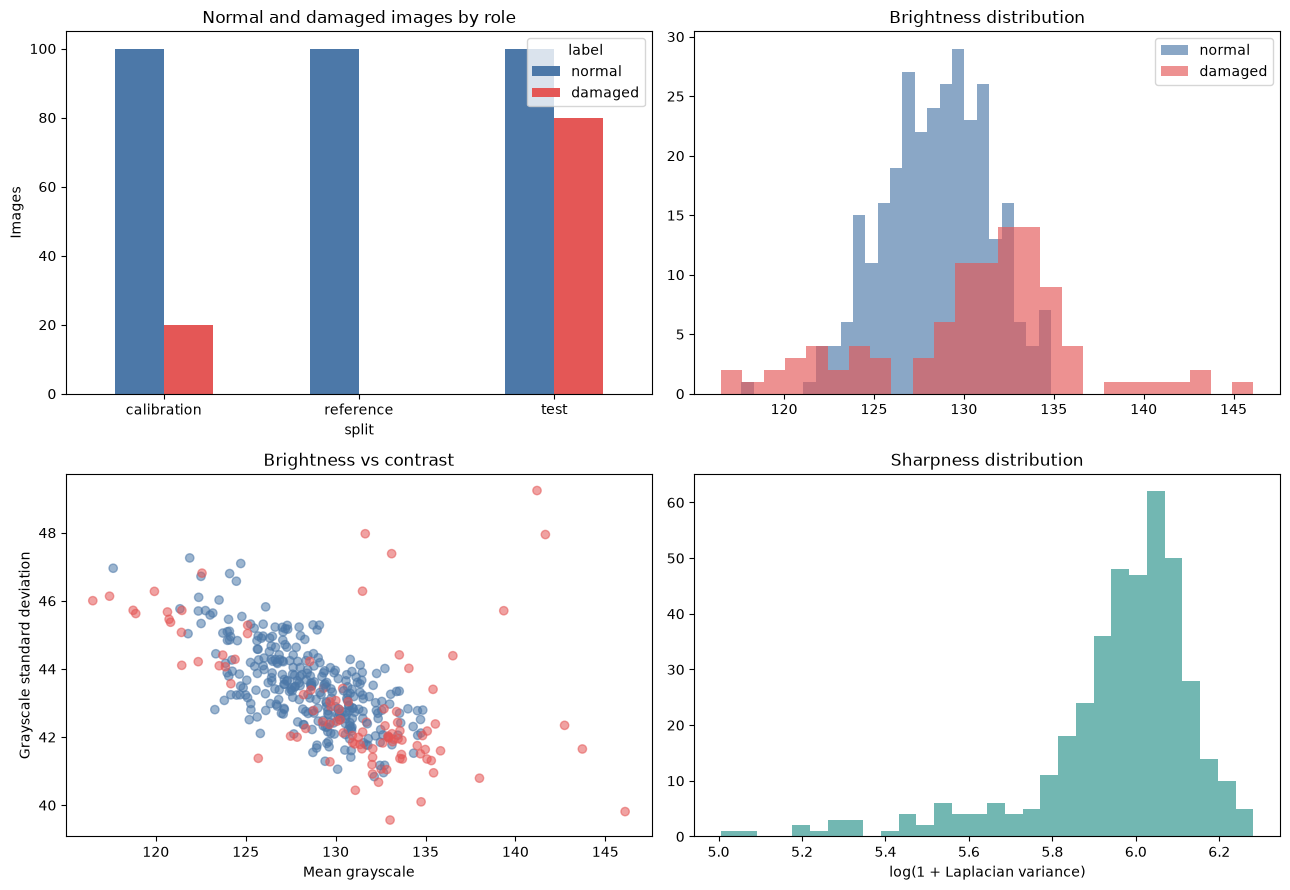

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
counts = audit.groupby(['split','label']).size().unstack(fill_value=0).rename(columns={0:'normal',1:'damaged'})
counts.plot(kind='bar', ax=axes[0,0], color=['#4C78A8','#E45756'], title='Normal and damaged images by role')
axes[0,0].set_ylabel('Images'); axes[0,0].tick_params(axis='x', rotation=0)
for label, color in [(0,'#4C78A8'),(1,'#E45756')]:
    values = audit.loc[audit.label == label, 'brightness'].dropna()
    axes[0,1].hist(values, bins=25, alpha=.65, label='normal' if label == 0 else 'damaged', color=color)
axes[0,1].set_title('Brightness distribution'); axes[0,1].legend()
axes[1,0].scatter(audit.brightness, audit.contrast, c=audit.label.map({0:'#4C78A8',1:'#E45756'}), alpha=.55)
axes[1,0].set(title='Brightness vs contrast', xlabel='Mean grayscale', ylabel='Grayscale standard deviation')
axes[1,1].hist(np.log1p(audit.blur_laplacian.dropna()), bins=30, color='#72B7B2')
axes[1,1].set(title='Sharpness distribution', xlabel='log(1 + Laplacian variance)')
plt.tight_layout(); plt.show()

### Image and mask examples

The red overlay is the dataset mask—not the model output. It shows where the labelled defect is located.

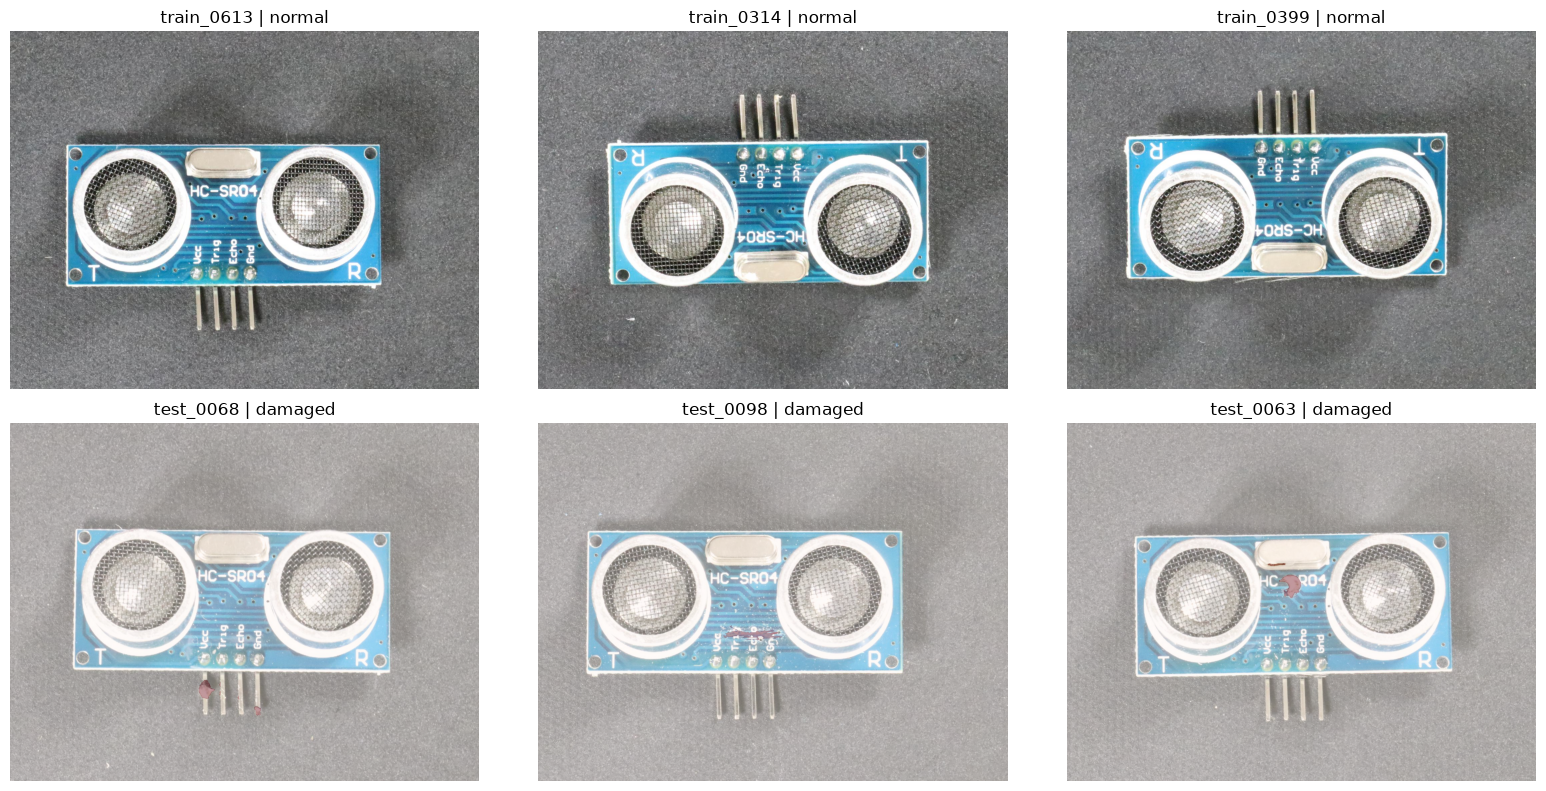

In [6]:
def load_rgb(row):
    with Image.open(absolute_path(row['image'])) as image:
        return np.asarray(image.convert('RGB'))

def load_mask(row):
    path = absolute_path(row['mask']) if row.get('mask') else None
    if path and path.is_file():
        with Image.open(path) as mask:
            return np.asarray(mask.convert('L')) > 0
    return None

examples = splits['reference'][:3] + [row for row in splits['calibration'] if row['label'] == 1][:3]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, row in zip(axes.flat, examples):
    rgb_image = load_rgb(row); mask = load_mask(row)
    ax.imshow(rgb_image)
    if mask is not None and mask.any(): ax.imshow(mask, cmap='Reds', alpha=.4)
    ax.set_title(f"{row['id']} | {'damaged' if row['label'] else 'normal'}")
    ax.axis('off')
plt.tight_layout(); plt.show()

## 3. ResNet-18 feature extractor

The classifier head is not trained. The existing ImageNet-pretrained ResNet-18 is frozen and used as a visual feature extractor. Features from `layer1`, `layer2`, and `layer3` are resized to the same spatial grid and concatenated. A deterministic subset of channels keeps covariance fitting manageable.

In [7]:
@dataclass(frozen=True)
class PadimConfig:
    image_size: int = 224
    feature_channels: int = 50
    covariance_regularization: float = 0.01
    smoothing_sigma: float = 4.0
    reference_count: int = 100
    batch_size: int = 8
    seed: int = SEED

    def validate(self, available_references):
        if self.image_size < 64 or self.image_size % 32 != 0:
            raise ValueError('image_size must be at least 64 and divisible by 32.')
        if not 2 <= self.feature_channels <= 448:
            raise ValueError('feature_channels must be between 2 and 448.')
        if not 0 < self.covariance_regularization <= 1:
            raise ValueError('covariance_regularization must be in (0, 1].')
        if self.smoothing_sigma < 0:
            raise ValueError('smoothing_sigma cannot be negative.')
        if not 2 <= self.reference_count <= available_references:
            raise ValueError(f'reference_count must be between 2 and {available_references}.')
        if self.batch_size < 1:
            raise ValueError('batch_size must be positive.')

class ResNet18Features(nn.Module):
    def __init__(self, weight_path, selected_channels, image_size):
        super().__init__()
        if not Path(weight_path).is_file():
            raise FileNotFoundError(f'Missing pretrained ResNet-18 weights: {weight_path}')
        backbone = resnet18(weights=None)
        backbone.load_state_dict(torch.load(weight_path, map_location='cpu', weights_only=True))
        self.stem = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool)
        self.layer1, self.layer2, self.layer3 = backbone.layer1, backbone.layer2, backbone.layer3
        self.register_buffer('mean', torch.tensor([.485,.456,.406]).reshape(1,3,1,1))
        self.register_buffer('std', torch.tensor([.229,.224,.225]).reshape(1,3,1,1))
        self.register_buffer('selected_channels', torch.as_tensor(selected_channels, dtype=torch.long))
        self.grid_size = image_size // 4
        for parameter in self.parameters(): parameter.requires_grad_(False)
        self.eval()

    def forward(self, x):
        x = (x - self.mean) / self.std
        first = self.layer1(self.stem(x))
        second = self.layer2(first)
        third = self.layer3(second)
        combined = torch.cat([first, F.interpolate(second, size=first.shape[-2:], mode='nearest'),
                              F.interpolate(third, size=first.shape[-2:], mode='nearest')], dim=1)
        return combined.index_select(1, self.selected_channels)

def preprocess(row, image_size):
    with Image.open(absolute_path(row['image'])) as image:
        array = np.asarray(image.convert('RGB').resize((image_size, image_size), Image.Resampling.BILINEAR), dtype=np.float32) / 255.0
    return torch.from_numpy(array.transpose(2,0,1).copy())


Input: (1, 3, 224, 224) Selected feature tensor: (1, 50, 56, 56)


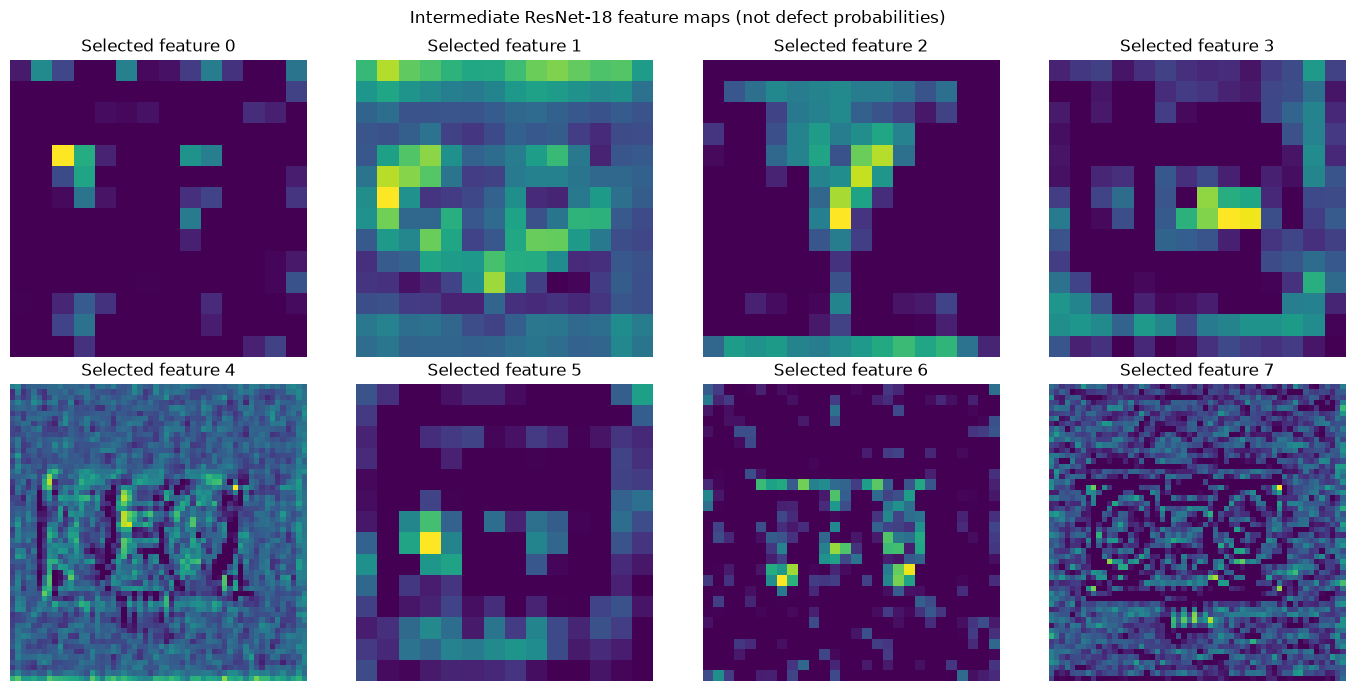

In [8]:
preview_config = PadimConfig()
preview_config.validate(len(splits['reference']))
preview_channels = np.random.default_rng(preview_config.seed).choice(448, preview_config.feature_channels, replace=False)
preview_extractor = ResNet18Features(WEIGHT_PATH, preview_channels, preview_config.image_size)
preview_input = preprocess(splits['reference'][0], preview_config.image_size).unsqueeze(0)
with torch.inference_mode(): preview_features = preview_extractor(preview_input)
print('Input:', tuple(preview_input.shape), 'Selected feature tensor:', tuple(preview_features.shape))
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for index, ax in enumerate(axes.flat):
    ax.imshow(preview_features[0,index].numpy(), cmap='viridis')
    ax.set_title(f'Selected feature {index}')
    ax.axis('off')
plt.suptitle('Intermediate ResNet-18 feature maps (not defect probabilities)')
plt.tight_layout(); plt.show()
del preview_extractor, preview_features, preview_input

## 4. PaDiM implementation

For each spatial location, PaDiM estimates a Gaussian distribution of normal ResNet features. At prediction time, the Mahalanobis distance from that normal distribution becomes an anomaly map. Covariance regularization prevents unstable matrix inversion; Gaussian smoothing reduces noisy local peaks.

In [9]:
class PCB1Padim:
    def __init__(self, config):
        config.validate(len(splits['reference']))
        self.config = config
        rng = np.random.default_rng(config.seed)
        self.channels = rng.choice(448, config.feature_channels, replace=False)
        self.extractor = ResNet18Features(WEIGHT_PATH, self.channels, config.image_size).to(DEVICE)
        self.mean = self.inverse_covariance = None

    @torch.inference_mode()
    def _embeddings(self, rows):
        chunks = []
        for start in range(0, len(rows), self.config.batch_size):
            batch = torch.stack([preprocess(row, self.config.image_size) for row in rows[start:start+self.config.batch_size]]).to(DEVICE)
            feature = self.extractor(batch).flatten(2).permute(0,2,1)
            chunks.append(feature.cpu())
        return torch.cat(chunks, dim=0)

    @torch.inference_mode()
    def fit(self, normal_rows):
        if len(normal_rows) < 2 or any(int(row.get('label', -1)) != 0 for row in normal_rows):
            raise ValueError('PaDiM fit requires at least two normal-only reference images.')
        embeddings = self._embeddings(normal_rows)
        self.mean = embeddings.mean(dim=0)
        centered = embeddings - self.mean.unsqueeze(0)
        location_first = centered.permute(1,2,0)
        identity = torch.eye(self.config.feature_channels).unsqueeze(0)
        covariance = torch.bmm(location_first, location_first.transpose(1,2)) / (len(embeddings)-1)
        covariance = covariance + self.config.covariance_regularization * identity
        self.inverse_covariance = torch.linalg.inv(covariance)
        if not torch.isfinite(self.inverse_covariance).all():
            raise ValueError('Covariance inversion produced non-finite values; increase regularization.')
        return self

    @torch.inference_mode()
    def predict(self, row):
        if self.mean is None: raise RuntimeError('Call fit() before predict().')
        embedding = self._embeddings([row])[0]
        difference = embedding - self.mean
        distance = torch.einsum('pd,pde,pe->p', difference, self.inverse_covariance, difference).clamp_min(0).sqrt()
        grid = self.config.image_size // 4
        anomaly_map = distance.reshape(1,1,grid,grid)
        anomaly_map = F.interpolate(anomaly_map, size=(self.config.image_size,self.config.image_size), mode='bilinear', align_corners=False)[0,0].numpy()
        if self.config.smoothing_sigma > 0:
            anomaly_map = cv2.GaussianBlur(anomaly_map, (0,0), self.config.smoothing_sigma)
        return float(anomaly_map.max()), anomaly_map

def fit_and_score(config, reference_rows, query_rows):
    config.validate(len(reference_rows))
    fit_rows = reference_rows[:config.reference_count]
    started = time.perf_counter(); model = PCB1Padim(config).fit(fit_rows); fit_seconds = time.perf_counter() - started
    records = []
    for row in query_rows:
        tick = time.perf_counter(); score, anomaly_map = model.predict(row)
        records.append({'id':row['id'], 'label':int(row['label']), 'score':score,
                        'seconds':time.perf_counter()-tick, 'anomaly_map':anomaly_map, 'row':row})
    return model, records, fit_seconds

## 5. Calibration threshold and metrics

The threshold is selected only on calibration data. Among thresholds with normal false-positive rate at or below the configured limit, the notebook chooses the one with the highest damaged-image recall. This reproduces the project's operating-point logic more faithfully than choosing the best-looking heatmaps.

In [10]:
def choose_threshold(records, max_normal_fpr=0.10):
    labels = np.asarray([record['label'] for record in records], dtype=int)
    scores = np.asarray([record['score'] for record in records], dtype=float)
    if set(labels) != {0,1}: raise ValueError('Calibration requires both normal and damaged images.')
    candidates = np.r_[np.nextafter(scores.min(), -np.inf), np.unique(scores)]
    choices = []
    for threshold in candidates:
        predicted = scores > threshold
        fp = int(((labels == 0) & predicted).sum()); tp = int(((labels == 1) & predicted).sum())
        fpr = fp / int((labels == 0).sum()); recall = tp / int((labels == 1).sum())
        if fpr <= max_normal_fpr: choices.append((recall, -fp, float(threshold)))
    if not choices: raise ValueError('No threshold satisfies the false-positive constraint.')
    return max(choices)[2]

def classification_metrics(records, threshold):
    labels = np.asarray([r['label'] for r in records], dtype=int)
    scores = np.asarray([r['score'] for r in records], dtype=float)
    predicted = scores > threshold
    tn, fp, fn, tp = confusion_matrix(labels, predicted, labels=[0,1]).ravel()
    return {'threshold':threshold, 'tp':int(tp), 'fn':int(fn), 'fp':int(fp), 'tn':int(tn),
            'recall':tp/(tp+fn), 'normal_fpr':fp/(fp+tn),
            'precision':tp/(tp+fp) if tp+fp else 0.0,
            'roc_auc':roc_auc_score(labels,scores), 'average_precision':average_precision_score(labels,scores),
            'median_seconds':float(np.median([r['seconds'] for r in records]))}

DEFAULT_CONFIG = PadimConfig()
default_model, calibration_records, default_fit_seconds = fit_and_score(DEFAULT_CONFIG, splits['reference'], splits['calibration'])
default_threshold = choose_threshold(calibration_records)
default_metrics = classification_metrics(calibration_records, default_threshold)
display(pd.DataFrame([{**asdict(DEFAULT_CONFIG), **default_metrics, 'fit_seconds':default_fit_seconds}]))

,image_size,feature_channels,covariance_regularization,smoothing_sigma,reference_count,batch_size,seed,threshold,tp,fn,fp,tn,recall,normal_fpr,precision,roc_auc,average_precision,median_seconds,fit_seconds
0,224,50,0.01,4.0,100,8,4217,11.102299,14,6,6,94,0.7,0.06,0.7,0.916,0.75715,0.057232,4.939471


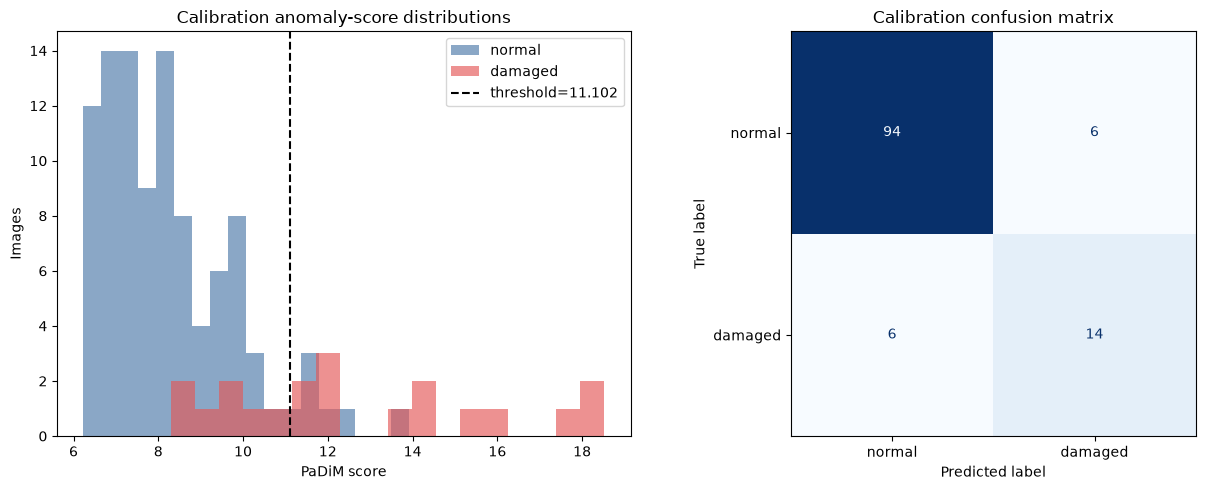

In [11]:
calibration_frame = pd.DataFrame([{k:v for k,v in record.items() if k not in ('anomaly_map','row')} for record in calibration_records])
calibration_frame['prediction'] = (calibration_frame.score > default_threshold).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for label, color, name in [(0,'#4C78A8','normal'),(1,'#E45756','damaged')]:
    axes[0].hist(calibration_frame.loc[calibration_frame.label==label,'score'], bins=18, alpha=.65, color=color, label=name)
axes[0].axvline(default_threshold, color='black', linestyle='--', label=f'threshold={default_threshold:.3f}')
axes[0].set(title='Calibration anomaly-score distributions', xlabel='PaDiM score', ylabel='Images'); axes[0].legend()
ConfusionMatrixDisplay.from_predictions(calibration_frame.label, calibration_frame.prediction, display_labels=['normal','damaged'], cmap='Blues', ax=axes[1], colorbar=False)
axes[1].set_title('Calibration confusion matrix')
plt.tight_layout(); plt.show()

## 6. Heatmap inspection and failure analysis

Use these plots to diagnose failure modes. A strong-looking heatmap is not sufficient: the image-level threshold still determines whether the product is flagged. Ground-truth masks are shown only for interpretation and are never used by the model.

False positives: 6 | Missed defects: 6 | Caught defects: 14


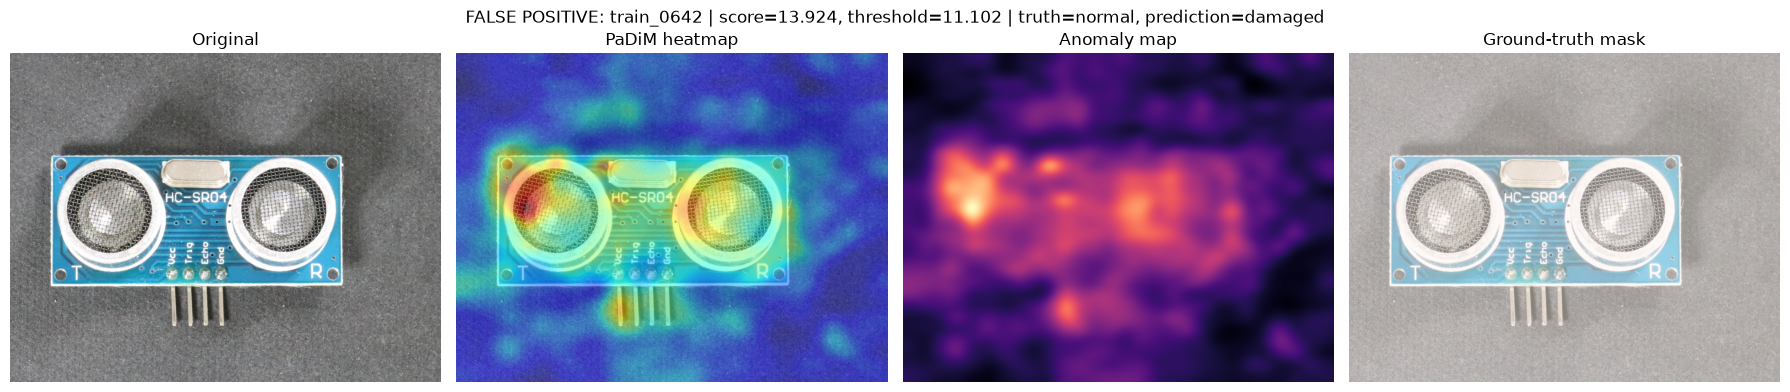

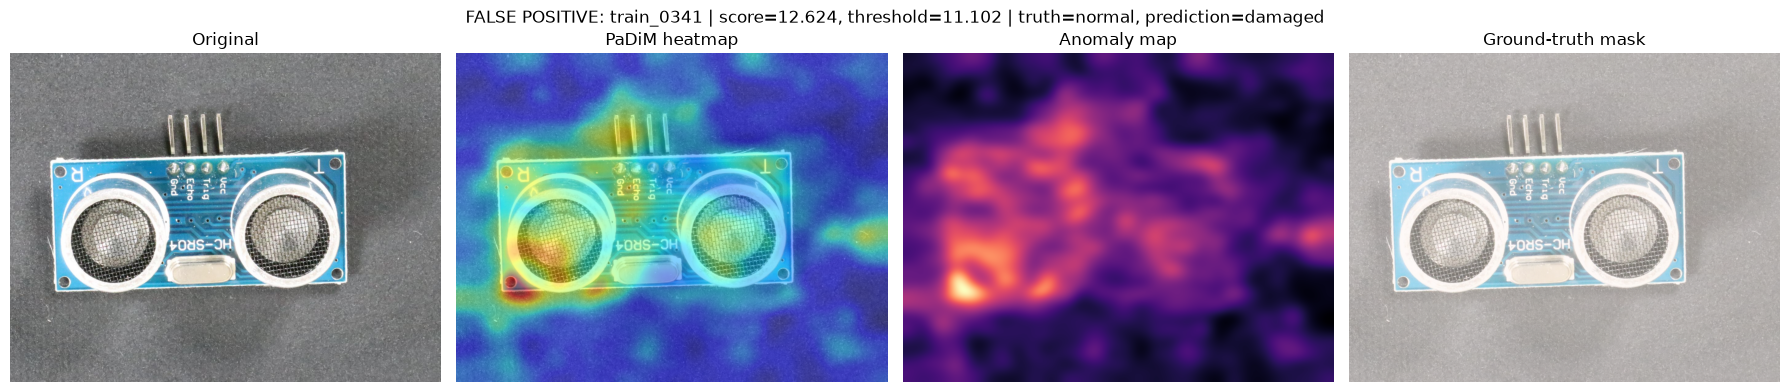

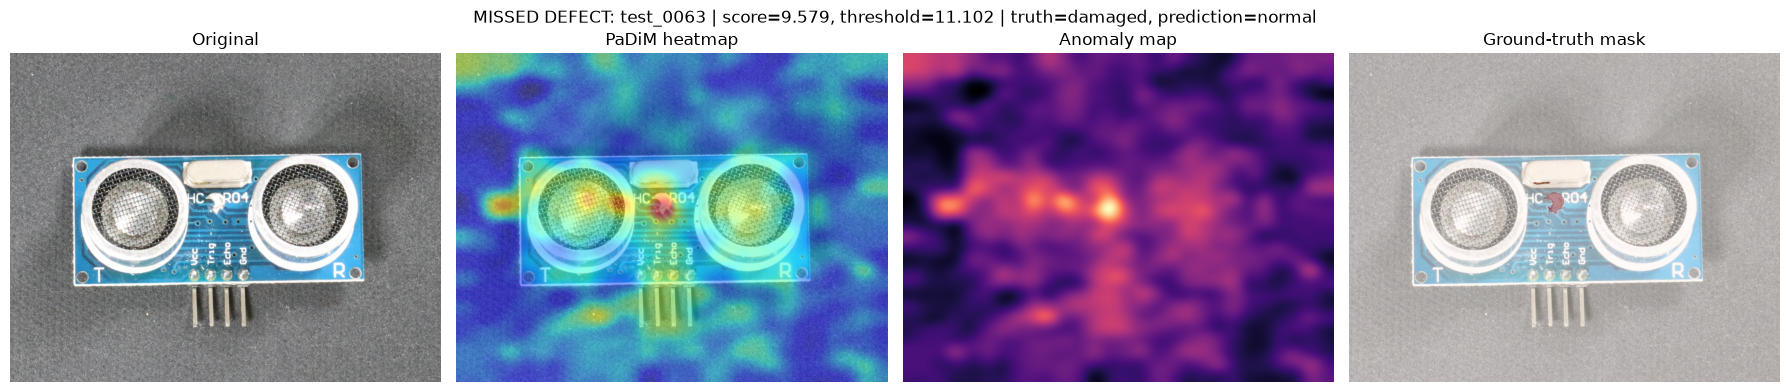

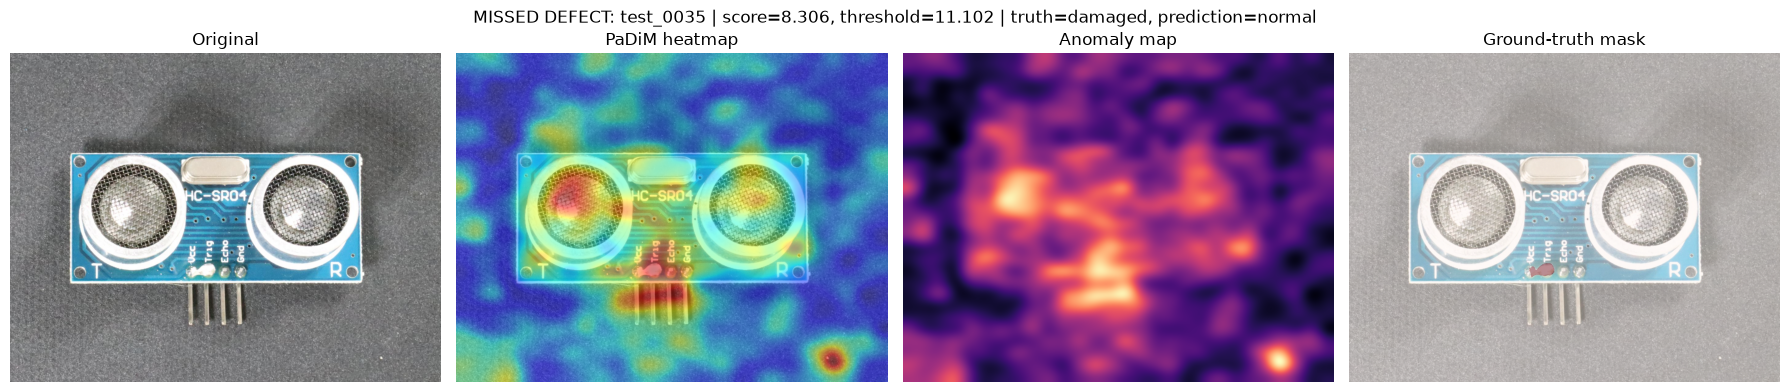

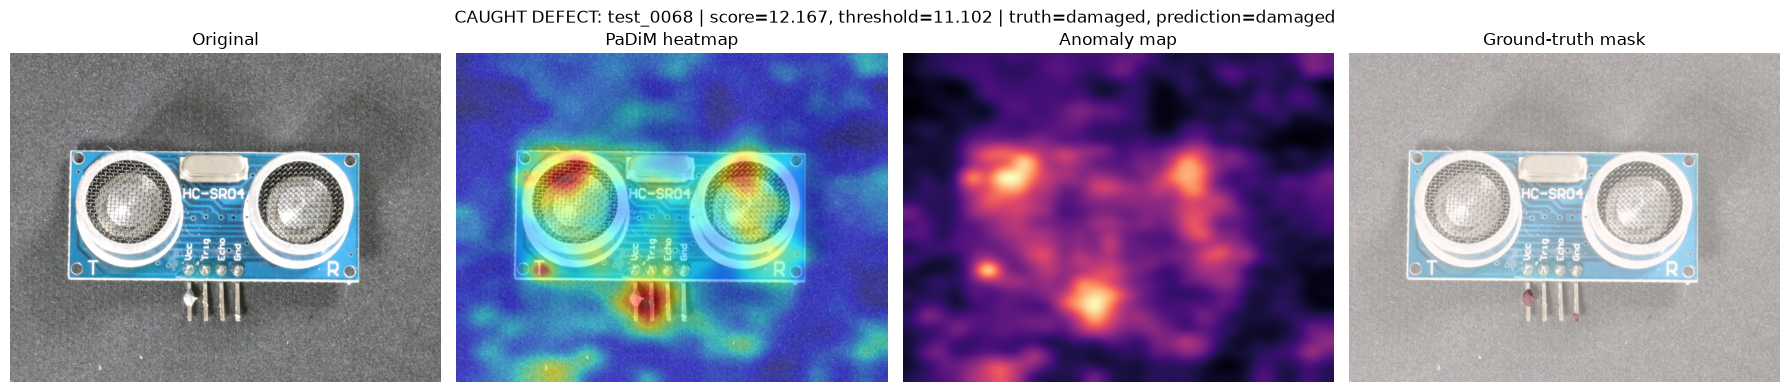

In [12]:
def show_prediction(record, threshold, title_prefix=''):
    row = record['row']; original = load_rgb(row); mask = load_mask(row)
    heat = cv2.resize(record['anomaly_map'], (original.shape[1], original.shape[0]), interpolation=cv2.INTER_LINEAR)
    scaled = (heat - heat.min()) / max(float(heat.max()-heat.min()), 1e-12)
    prediction = int(record['score'] > threshold)
    fig, axes = plt.subplots(1, 4, figsize=(18, 4))
    axes[0].imshow(original); axes[0].set_title('Original')
    axes[1].imshow(original); axes[1].imshow(scaled, cmap='jet', alpha=.5); axes[1].set_title('PaDiM heatmap')
    axes[2].imshow(scaled, cmap='magma'); axes[2].set_title('Anomaly map')
    axes[3].imshow(original)
    if mask is not None: axes[3].imshow(mask, cmap='Reds', alpha=.45)
    axes[3].set_title('Ground-truth mask')
    for ax in axes: ax.axis('off')
    status = f"truth={'damaged' if record['label'] else 'normal'}, prediction={'damaged' if prediction else 'normal'}"
    fig.suptitle(f"{title_prefix}{row['id']} | score={record['score']:.3f}, threshold={threshold:.3f} | {status}")
    plt.tight_layout(); plt.show()

false_positives = [r for r in calibration_records if r['label']==0 and r['score']>default_threshold]
false_negatives = [r for r in calibration_records if r['label']==1 and r['score']<=default_threshold]
true_positives = [r for r in calibration_records if r['label']==1 and r['score']>default_threshold]
print('False positives:', len(false_positives), '| Missed defects:', len(false_negatives), '| Caught defects:', len(true_positives))
for collection, name in [(false_positives[:2],'FALSE POSITIVE: '), (false_negatives[:2],'MISSED DEFECT: '), (true_positives[:1],'CAUGHT DEFECT: ')]:
    for record in collection: show_prediction(record, default_threshold, name)

## 7. Calibration parameter search

Edit the grid conservatively. Each combination refits PaDiM and scores the calibration set. The table ranks configurations by recall, then lower false-positive rate, then speed. This is exploratory tuning, not independent validation.

In [13]:
PARAMETER_GRID = {
    'image_size': [160, 224],
    'feature_channels': [25, 50],
    'covariance_regularization': [0.01, 0.05],
    'smoothing_sigma': [2.0, 4.0],
    'reference_count': [50, 100],
}

def configurations_from_grid(grid, max_trials=MAX_TRIALS):
    names = list(grid); combinations = list(product(*(grid[name] for name in names)))
    if len(combinations) > max_trials:
        warnings.warn(f'Grid contains {len(combinations)} trials; using the first {max_trials}. Adjust MAX_TRIALS deliberately to run more.')
        combinations = combinations[:max_trials]
    return [PadimConfig(**dict(zip(names, values))) for values in combinations]

search_results = []
if RUN_PARAMETER_SEARCH:
    for trial, config in enumerate(configurations_from_grid(PARAMETER_GRID), start=1):
        print(f'Trial {trial}: {config}')
        _, records, fit_seconds = fit_and_score(config, splits['reference'], splits['calibration'])
        threshold = choose_threshold(records, max_normal_fpr=.10)
        search_results.append({**asdict(config), **classification_metrics(records, threshold), 'fit_seconds':fit_seconds})
    search_table = pd.DataFrame(search_results).sort_values(['recall','normal_fpr','median_seconds'], ascending=[False,True,True])
    stamp = datetime.now().strftime('%Y%m%d-%H%M%S')
    search_table.to_csv(OUTPUT_ROOT / f'pcb1_padim_calibration_search_{stamp}.csv', index=False)
    display(search_table)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    points = axes[0].scatter(search_table.normal_fpr, search_table.recall, c=search_table.feature_channels, s=70, cmap='viridis')
    axes[0].set(xlabel='Normal false-positive rate', ylabel='Damaged-image recall', title='Calibration trade-off')
    fig.colorbar(points, ax=axes[0], label='Feature channels')
    search_table.plot(x='reference_count', y='fit_seconds', kind='scatter', c='image_size', colormap='plasma', s=70, ax=axes[1], title='Fit cost')
    plt.tight_layout(); plt.show()
else:
    print('Parameter search is disabled. Set RUN_PARAMETER_SEARCH = True after understanding the single run.')

Parameter search is disabled. Set RUN_PARAMETER_SEARCH = True after understanding the single run.


## 8. Optional final test

Do not repeatedly tune against this result. Select one configuration from calibration first, record it, then set `RUN_FINAL_TEST = True` and run this cell once. If you change parameters after seeing test failures, you need a new untouched holdout for an honest evaluation.

In [14]:
SELECTED_CONFIG = DEFAULT_CONFIG  # Replace only using calibration-search evidence.
SELECTED_THRESHOLD = default_threshold

if RUN_FINAL_TEST:
    final_model, final_records, final_fit_seconds = fit_and_score(SELECTED_CONFIG, splits['reference'], splits['test'])
    final_metrics = classification_metrics(final_records, SELECTED_THRESHOLD)
    final_summary = {**asdict(SELECTED_CONFIG), **final_metrics, 'fit_seconds':final_fit_seconds,
                     'warning':'Final test inspected; do not reuse it for tuning.'}
    display(pd.DataFrame([final_summary]))
    labels = [r['label'] for r in final_records]; predictions = [int(r['score'] > SELECTED_THRESHOLD) for r in final_records]
    ConfusionMatrixDisplay.from_predictions(labels, predictions, display_labels=['normal','damaged'], cmap='Blues', colorbar=False)
    plt.title('Untouched final-test confusion matrix'); plt.show()
    stamp = datetime.now().strftime('%Y%m%d-%H%M%S')
    with (OUTPUT_ROOT / f'pcb1_padim_final_test_{stamp}.json').open('x', encoding='utf-8') as handle:
        json.dump(final_summary, handle, indent=2)
else:
    print('Final test remains untouched. Set RUN_FINAL_TEST = True only after selecting parameters from calibration.')

Final test remains untouched. Set RUN_FINAL_TEST = True only after selecting parameters from calibration.


## 9. What to investigate when the model fails

1. **Orientation and alignment:** PaDiM models each spatial location, so rotated or shifted normal boards can look anomalous.
2. **Small defects after resizing:** resizing the whole PCB to 224×224 may erase small scratches or missing details.
3. **Too few feature channels:** the compact 50-channel model may discard useful signals. More channels cost much more covariance memory.
4. **Covariance stability:** too little regularization can amplify noise; too much can wash out meaningful variation.
5. **Normal variation:** a reference set that does not represent harmless positions, lighting, or board variation causes false positives.
6. **Threshold trade-off:** raising recall usually increases false alarms. Inspect the calibration trade-off chart rather than optimizing accuracy alone.
7. **Dataset transfer:** PCB1 benchmark images do not prove performance on phone photographs or factory conditions.

The most informative next experiment is usually a controlled crop/alignment study with a new holdout—not a large blind grid search.